# Sequential models: from AR to ARX to an RNN

<a target="_blank" href="https://colab.research.google.com/github/changyaochen/MECE4520/blob/master/site/sequential-models/02-silverbox-arx-rnn.ipynb"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open in Colab"/></a>

The [Silverbox benchmark](https://www.nonlinearbenchmark.org/benchmarks/silverbox) records the response of an electronic system designed to behave like a Duffing oscillator. It provides one deliberately applied input, `V1`, and one measured response, `V2`. A useful mechanical analogy is a force-like excitation $u_t$ and a displacement-like response $y_t$.

We will predict the next response using information available at that time. The three models below use past responses, the known input, or a learned nonlinear recurrent state representation.

## What you will do

1. Load one real input--response system-identification benchmark.
2. Preserve its chronological training/test experiment split.
3. Fit an AR(20) model using only past response values.
4. Add the known forcing signal to create an ARX(20) model.
5. Fit a small RNN that can learn a nonlinear representation of a recent input--response sequence.
6. Compare all three models using a free-run, recursive held-out forecast.

## 1. Load the measured input--response experiments

The `nonlinear-benchmarks` package downloads the official Silverbox record to the notebook runtime. Nothing is fitted to the held-out experiment.

In [1]:
# This package downloads the official Silverbox benchmark when it is first used.
try:
    from nonlinear_benchmarks import Silverbox
except ModuleNotFoundError:
    %pip install -q nonlinear-benchmarks
    from nonlinear_benchmarks import Silverbox

from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler

sns.set_theme(style="whitegrid", context="notebook")
RANDOM_SEED = 7
np.random.seed(RANDOM_SEED)
torch.manual_seed(RANDOM_SEED)

# Use the GPU in Colab when one is available; otherwise PyTorch uses the CPU.
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"PyTorch device: {device}")

PyTorch device: cpu


In [2]:
# Store the official download in the notebook's local working directory.
# In Colab, this directory is temporary and disappears when the runtime ends.
benchmark_directory = Path("silverbox-data")
benchmark_directory.mkdir(exist_ok=True)
training_record, test_records = Silverbox(dir_placement=benchmark_directory)
test_record = test_records[0]  # The official held-out multisine experiment.

u_train = np.asarray(training_record.u, dtype=float).reshape(-1)
y_train = np.asarray(training_record.y, dtype=float).reshape(-1)
u_test = np.asarray(test_record.u, dtype=float).reshape(-1)
y_test = np.asarray(test_record.y, dtype=float).reshape(-1)
sampling_time = float(training_record.sampling_time)

print(f"Training samples: {len(y_train):,}")
print(f"Held-out samples: {len(y_test):,}")
print(f"Sampling interval: {sampling_time * 1_000:.4f} ms")

dataset not found downloading from https://drive.google.com/file/d/17iS-6oBUUgrmiAcrZoG9S5sOaljZnDSy/view 
 in silverbox-data/Silverbox/SilverboxFiles.zip


extracting file...
save_loc='silverbox-data/Silverbox/SilverboxFiles.zip'
Training samples: 65,062
Held-out samples: 21,688
Sampling interval: 1.6384 ms


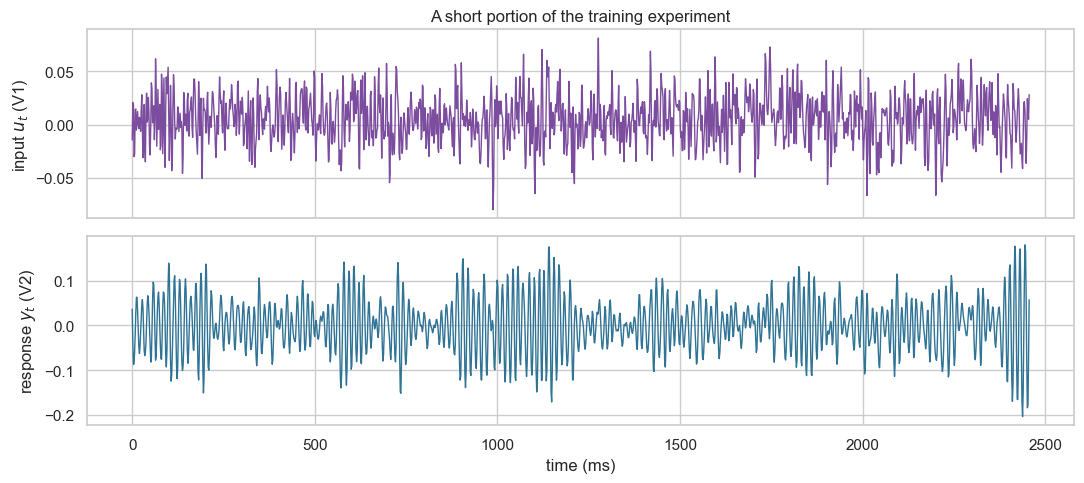

In [3]:
display_samples = 1_500
time_ms = np.arange(display_samples) * sampling_time * 1_000

fig, axes = plt.subplots(2, 1, figsize=(11, 5), sharex=True)
axes[0].plot(time_ms, u_train[:display_samples], color="#7c4d9e", linewidth=1)
axes[0].set(ylabel="input $u_t$ (V1)", title="A short portion of the training experiment")
axes[1].plot(time_ms, y_train[:display_samples], color="#2f7395", linewidth=1)
axes[1].set(xlabel="time (ms)", ylabel="response $y_t$ (V2)")
plt.tight_layout()
plt.show()

## 2. Use one free-run held-out forecasting protocol

All three models use the first $p=20$ measured responses in the held-out experiment only to initialize their state. Afterwards, each predicted response becomes part of the next input window. The later true responses are **not** fed back to the model. This is harder, but it represents a genuine multi-step forecast.

The applied input $u_t$ remains known throughout the held-out experiment. That is natural in system identification: it is an externally imposed forcing signal, not an unknown future measurement.

For the two linear models, we use

$$
\begin{aligned}
\text{AR}(p):\quad \widehat{y}_t &= \beta_0 + \sum_{j=1}^{p}\beta_j y_{t-j},\\
\text{ARX}(p):\quad \widehat{y}_t &= \beta_0 + \sum_{j=1}^{p}\beta_j y_{t-j} + \sum_{j=0}^{p}\gamma_j u_{t-j}.
\end{aligned}
$$

In [4]:
ORDER = 20


def make_linear_design(
    *,
    input_signal: np.ndarray,
    output_signal: np.ndarray,
    order: int,
    include_input: bool,
) -> tuple[np.ndarray, np.ndarray]:
    """Build one-step input rows for an AR or ARX model.

    Args:
        input_signal: Known forcing values $u_t$ from one experiment.
        output_signal: Measured response values $y_t$ from one experiment.
        order: Number of earlier response values to include.
        include_input: Whether to append the current and lagged input values.

    Returns:
        A feature matrix and matching next-response target vector.
    """
    rows: list[np.ndarray] = []
    targets: list[float] = []
    for index in range(order, len(output_signal)):
        response_lags = output_signal[index - order : index][::-1]
        if include_input:
            input_lags = input_signal[index - order : index + 1][::-1]
            rows.append(np.concatenate((response_lags, input_lags)))
        else:
            rows.append(response_lags)
        targets.append(output_signal[index])
    return np.asarray(rows), np.asarray(targets)


def fit_linear_forecaster(
    *,
    input_signal: np.ndarray,
    output_signal: np.ndarray,
    order: int,
    include_input: bool,
) -> tuple[StandardScaler, Ridge]:
    """Fit an almost-unregularized linear AR or ARX forecaster.

    Args:
        input_signal: Known forcing values from the training experiment.
        output_signal: Measured training responses.
        order: Number of earlier response values to use.
        include_input: Whether to fit an ARX model instead of an AR model.

    Returns:
        The training-only feature scaler and fitted linear model.
    """
    features, targets = make_linear_design(
        input_signal=input_signal,
        output_signal=output_signal,
        order=order,
        include_input=include_input,
    )
    scaler = StandardScaler().fit(features)
    model = Ridge(alpha=1e-7).fit(scaler.transform(features), targets)
    return scaler, model


def recursive_linear_forecast(
    *,
    input_signal: np.ndarray,
    observed_output: np.ndarray,
    order: int,
    include_input: bool,
    scaler: StandardScaler,
    model: Ridge,
) -> np.ndarray:
    """Make a free-run forecast after an initial measured response window.

    Args:
        input_signal: Known input values for the held-out experiment.
        observed_output: Held-out responses; only the first `order` values initialize history.
        order: Number of prior responses in every forecast feature row.
        include_input: Whether to use the known input values (ARX).
        scaler: Feature scaler fitted using training rows only.
        model: Fitted AR or ARX linear model.

    Returns:
        Predictions with `np.nan` during the initialization window.
    """
    history = list(observed_output[:order])
    predictions = np.full(len(observed_output), np.nan)
    for index in range(order, len(observed_output)):
        response_lags = np.asarray(history[-order:][::-1])
        if include_input:
            input_lags = input_signal[index - order : index + 1][::-1]
            feature_row = np.concatenate((response_lags, input_lags))
        else:
            feature_row = response_lags
        prediction = model.predict(scaler.transform(feature_row.reshape(1, -1)))[0]
        history.append(float(prediction))  # Later lags are predictions, not labels.
        predictions[index] = prediction
    return predictions


def rmse(*, actual: np.ndarray, predicted: np.ndarray, warmup: int) -> float:
    """Calculate root-mean-square error after the initialization window.

    Args:
        actual: Observed held-out response values.
        predicted: Recursive forecasts aligned with `actual`.
        warmup: Number of initial values excluded from scoring.

    Returns:
        The held-out free-run RMSE.
    """
    return float(np.sqrt(np.mean((actual[warmup:] - predicted[warmup:]) ** 2)))

## 3. Start with a response-only AR(20) model

The AR model has 20 lagged `V2` values but no access to `V1`. It must infer any future response solely from its own earlier response forecasts.

In [5]:
ar_scaler, ar_model = fit_linear_forecaster(
    input_signal=u_train,
    output_signal=y_train,
    order=ORDER,
    include_input=False,
)
ar_prediction = recursive_linear_forecast(
    input_signal=u_test,
    observed_output=y_test,
    order=ORDER,
    include_input=False,
    scaler=ar_scaler,
    model=ar_model,
)
ar_rmse = rmse(actual=y_test, predicted=ar_prediction, warmup=ORDER)
print(f"AR({ORDER}) recursive held-out RMSE: {ar_rmse:.5f}")

AR(20) recursive held-out RMSE: 0.05429


## 4. Add the causal forcing signal: ARX(20)

The ARX model receives the same response history plus the current and 20 previous `V1` values. Because `V1` is deliberately imposed on the physical system, it is reasonable to treat it as known at prediction time. This is different from leaking later `V2` labels into the model.

ARX(20) recursive held-out RMSE: 0.00694


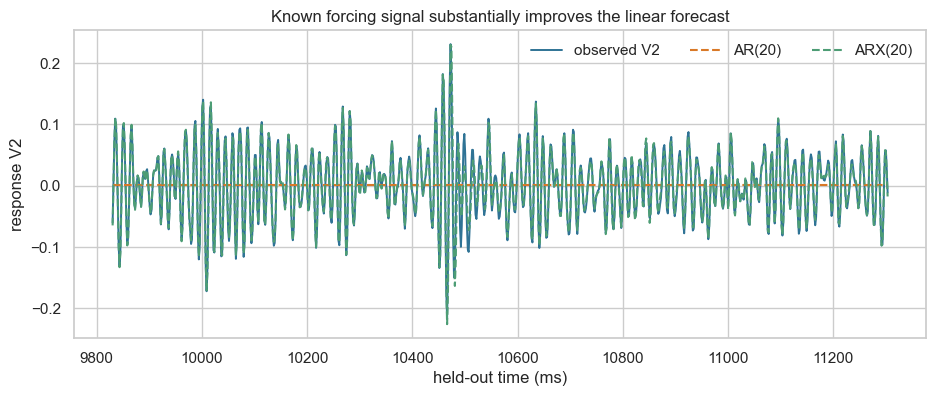

In [6]:
arx_scaler, arx_model = fit_linear_forecaster(
    input_signal=u_train,
    output_signal=y_train,
    order=ORDER,
    include_input=True,
)
arx_prediction = recursive_linear_forecast(
    input_signal=u_test,
    observed_output=y_test,
    order=ORDER,
    include_input=True,
    scaler=arx_scaler,
    model=arx_model,
)
arx_rmse = rmse(actual=y_test, predicted=arx_prediction, warmup=ORDER)
print(f"ARX({ORDER}) recursive held-out RMSE: {arx_rmse:.5f}")

window_start = 6_000
window_length = 900
window = slice(window_start, window_start + window_length)
window_time = np.arange(window_start, window_start + window_length) * sampling_time * 1_000

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(window_time, y_test[window], color="#2f7395", linewidth=1.4, label="observed V2")
ax.plot(window_time, ar_prediction[window], color="#d97927", linestyle="--", label="AR(20)")
ax.plot(window_time, arx_prediction[window], color="#4d9d75", linestyle="--", label="ARX(20)")
ax.set(xlabel="held-out time (ms)", ylabel="response V2", title="Known forcing signal substantially improves the linear forecast")
ax.legend(frameon=False, ncol=3)
plt.show()

## 5. Learn a nonlinear state with a small RNN

An RNN is not limited to a fixed linear weighted sum of the lagged values. At each position in a sequence, it updates a hidden state. Here, the RNN reads pairs of known input and previous response values, then predicts the next response:

$$
h_t = \tanh(W_h h_{t-1} + W_y y_{t-1} + W_u u_t + b_h),
\qquad \widehat{y}_t = f(h_t).
$$

For a transparent comparison with ARX(20), each prediction below rebuilds an RNN state from a recent 20-sample window. During the recursive test forecast, those windows contain past **predicted** responses after initialization.

In [7]:
class RecurrentPredictor(torch.nn.Module):
    """Map a recent input--response sequence to the next response.

    Args:
        hidden_size: Number of values carried by the learned recurrent state.
    """

    def __init__(self, *, hidden_size: int) -> None:
        super().__init__()
        self.rnn = torch.nn.RNN(
            input_size=2,  # [known input, previous response]
            hidden_size=hidden_size,
            batch_first=True,
            nonlinearity="tanh",
        )
        self.readout = torch.nn.Sequential(
            torch.nn.Linear(hidden_size, hidden_size),
            torch.nn.Tanh(),
            torch.nn.Linear(hidden_size, 1),
        )

    def forward(self, sequence: torch.Tensor) -> torch.Tensor:
        """Predict one next standardized response for each sequence.

        Args:
            sequence: Tensor of shape `(batch, time, 2)`.

        Returns:
            A length-`batch` vector of standardized next-response predictions.
        """
        hidden_values, _ = self.rnn(sequence)
        return self.readout(hidden_values[:, -1, :]).squeeze(-1)


def make_rnn_windows(
    *,
    input_signal: np.ndarray,
    output_signal: np.ndarray,
    order: int,
) -> tuple[np.ndarray, np.ndarray]:
    """Create `[input, previous response]` RNN windows and next targets.

    Args:
        input_signal: Standardized known forcing signal.
        output_signal: Standardized response signal.
        order: Number of sequence positions in every input window.

    Returns:
        A sequence tensor with shape `(samples, order, 2)` and a target vector.
    """
    sequences: list[np.ndarray] = []
    targets: list[float] = []
    for index in range(order, len(output_signal)):
        positions = np.arange(index - order + 1, index + 1)
        sequences.append(
            np.column_stack((input_signal[positions], output_signal[positions - 1]))
        )
        targets.append(output_signal[index])
    return np.asarray(sequences, dtype=np.float32), np.asarray(targets, dtype=np.float32)


def recursive_rnn_forecast(
    *,
    model: RecurrentPredictor,
    input_signal: np.ndarray,
    observed_output: np.ndarray,
    order: int,
    input_mean: float,
    input_std: float,
    output_mean: float,
    output_std: float,
) -> np.ndarray:
    """Make a recursive held-out RNN forecast using only known forcing values.

    Args:
        model: Trained RNN that predicts standardized responses.
        input_signal: Known held-out forcing signal.
        observed_output: Held-out response; only the first `order` values initialize history.
        order: Length of each RNN input window.
        input_mean: Training-input mean.
        input_std: Training-input standard deviation.
        output_mean: Training-output mean.
        output_std: Training-output standard deviation.

    Returns:
        Recursive predictions aligned with the held-out response.
    """
    history = list(observed_output[:order])
    predictions = np.full(len(observed_output), np.nan)
    model.eval()
    with torch.no_grad():
        for index in range(order, len(observed_output)):
            positions = np.arange(index - order + 1, index + 1)
            previous_responses = np.asarray([history[position - 1] for position in positions])
            sequence = np.column_stack((
                (input_signal[positions] - input_mean) / input_std,
                (previous_responses - output_mean) / output_std,
            )).astype(np.float32)
            tensor = torch.from_numpy(sequence[None, ...]).to(device)
            standardized_prediction = model(tensor).item()
            prediction = standardized_prediction * output_std + output_mean
            history.append(prediction)
            predictions[index] = prediction
    return predictions

In [8]:
# Standardization statistics are learned from the training experiment only.
u_mean, u_std = float(u_train.mean()), float(u_train.std())
y_mean, y_std = float(y_train.mean()), float(y_train.std())
u_train_scaled = (u_train - u_mean) / u_std
y_train_scaled = (y_train - y_mean) / y_std
train_sequences, train_targets = make_rnn_windows(
    input_signal=u_train_scaled,
    output_signal=y_train_scaled,
    order=ORDER,
)

HIDDEN_SIZE = 16
EPOCHS = 150
BATCH_SIZE = 128
BATCHES_PER_EPOCH = 32

rnn_model = RecurrentPredictor(hidden_size=HIDDEN_SIZE).to(device)
optimizer = torch.optim.Adam(rnn_model.parameters(), lr=0.003, weight_decay=1e-5)
loss_function = torch.nn.MSELoss()
generator = np.random.default_rng(RANDOM_SEED)
training_losses: list[float] = []

for epoch in range(EPOCHS):
    rnn_model.train()
    batch_losses: list[float] = []
    for _ in range(BATCHES_PER_EPOCH):
        chosen_rows = generator.integers(0, len(train_sequences), size=BATCH_SIZE)
        sequence_batch = torch.from_numpy(train_sequences[chosen_rows]).to(device)
        target_batch = torch.from_numpy(train_targets[chosen_rows]).to(device)

        optimizer.zero_grad()  # PyTorch otherwise accumulates gradients from earlier batches.
        prediction_batch = rnn_model(sequence_batch)
        loss = loss_function(prediction_batch, target_batch)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(rnn_model.parameters(), max_norm=1.0)
        optimizer.step()
        batch_losses.append(loss.item())
    training_losses.append(float(np.mean(batch_losses)))
    if (epoch + 1) % 20 == 0:
        print(f"Epoch {epoch + 1:>3}: mean batch MSE = {training_losses[-1]:.5f}")

Epoch  20: mean batch MSE = 0.00046


Epoch  40: mean batch MSE = 0.00029


Epoch  60: mean batch MSE = 0.00019


Epoch  80: mean batch MSE = 0.00014


Epoch 100: mean batch MSE = 0.00006


Epoch 120: mean batch MSE = 0.00009


Epoch 140: mean batch MSE = 0.00004


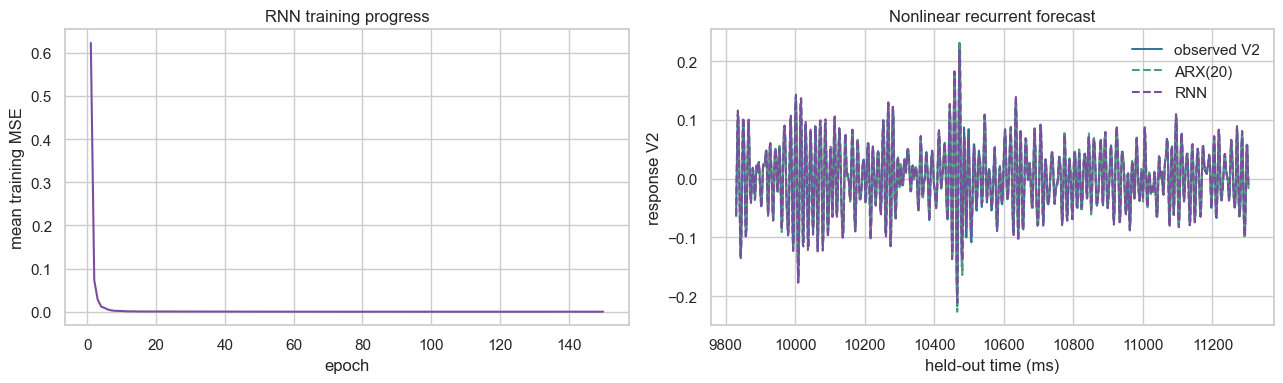

,model,information available,recursive held-out RMSE
0,AR(20),past response only,0.05429
1,ARX(20),past response + known forcing input,0.00694
2,small RNN,recent input--response sequence + learned nonlinear state,0.00173


In [9]:
rnn_prediction = recursive_rnn_forecast(
    model=rnn_model,
    input_signal=u_test,
    observed_output=y_test,
    order=ORDER,
    input_mean=u_mean,
    input_std=u_std,
    output_mean=y_mean,
    output_std=y_std,
)
rnn_rmse = rmse(actual=y_test, predicted=rnn_prediction, warmup=ORDER)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(np.arange(1, EPOCHS + 1), training_losses, color="#7c4d9e")
axes[0].set(xlabel="epoch", ylabel="mean training MSE", title="RNN training progress")
axes[1].plot(window_time, y_test[window], color="#2f7395", linewidth=1.4, label="observed V2")
axes[1].plot(window_time, arx_prediction[window], color="#4d9d75", linestyle="--", label="ARX(20)")
axes[1].plot(window_time, rnn_prediction[window], color="#7c4d9e", linestyle="--", label="RNN")
axes[1].set(xlabel="held-out time (ms)", ylabel="response V2", title="Nonlinear recurrent forecast")
axes[1].legend(frameon=False)
plt.tight_layout()
plt.show()

comparison = pd.DataFrame({
    "model": [f"AR({ORDER})", f"ARX({ORDER})", "small RNN"],
    "information available": [
        "past response only",
        "past response + known forcing input",
        "recent input--response sequence + learned nonlinear state",
    ],
    "recursive held-out RMSE": [ar_rmse, arx_rmse, rnn_rmse],
})
display(comparison.style.format({"recursive held-out RMSE": "{:.5f}"}))

## What this comparison does—and does not—show

- Adding `V1` helps because it is a known causal input that drives the system; AR cannot react to it directly.
- The RNN can learn nonlinear effects in a recent history, which is useful for this Duffing-like system.
- This does **not** make an RNN automatically preferable. The fair comparison is always on future or held-out experiments, with only information available at the forecasting time.
- A nonlinear fixed-window model, a different RNN architecture, or a different input horizon could also improve this task.

<p style="margin-top: 1.5rem;"><a href="index.html">← Return to Sequential models</a></p>